<a href="https://colab.research.google.com/github/garvitSharma24112/machine-learning/blob/main/Naives_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using Colab cache for faster access to the 'color-balls-decision-trees' dataset.
Path to dataset files: /kaggle/input/color-balls-decision-trees
Contents of directory /kaggle/input/color-balls-decision-trees:
- Color Balls_Train.csv
- .nfs00000000ad45f4200000008d
- Color Balls_Test.csv
Found Train CSV file at: /kaggle/input/color-balls-decision-trees/Color Balls_Train.csv
Columns in training dataset: ['Room', 'Partitions', 'Rows', 'Columns', 'Color']
First 5 rows of the training dataset:


,Room,Partitions,Rows,Columns,Color
0,2,2,2,1,Red
1,3,1,2,1,Red
2,3,2,1,2,Red
3,2,3,1,2,Blue
4,4,2,1,2,Yellow


Found Test CSV file at: /kaggle/input/color-balls-decision-trees/Color Balls_Test.csv
Columns in prediction features dataset: ['Room', 'Partitions', 'Rows', 'Columns']
First 5 rows of the prediction features dataset:


,Room,Partitions,Rows,Columns
0,4,2,1,1
1,3,2,1,1
2,2,2,1,1
3,2,2,2,2
4,1,2,2,2



--- Applying Naive Bayes Classification (Training Data) ---
Naive Bayes Accuracy on validation set: 0.57

Classification Report on validation set:
              precision    recall  f1-score   support

        Blue       0.64      0.23      0.33        31
       Green       0.56      0.60      0.58        15
         Red       0.60      0.52      0.56        46
      Yellow       0.53      1.00      0.69        28

    accuracy                           0.57       120
   macro avg       0.58      0.59      0.54       120
weighted avg       0.59      0.57      0.53       120



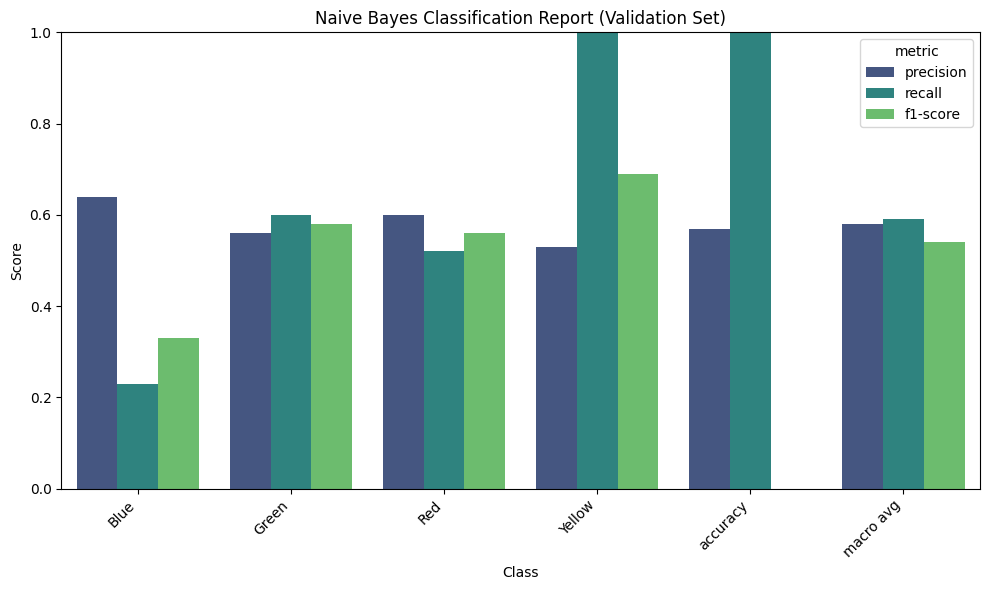

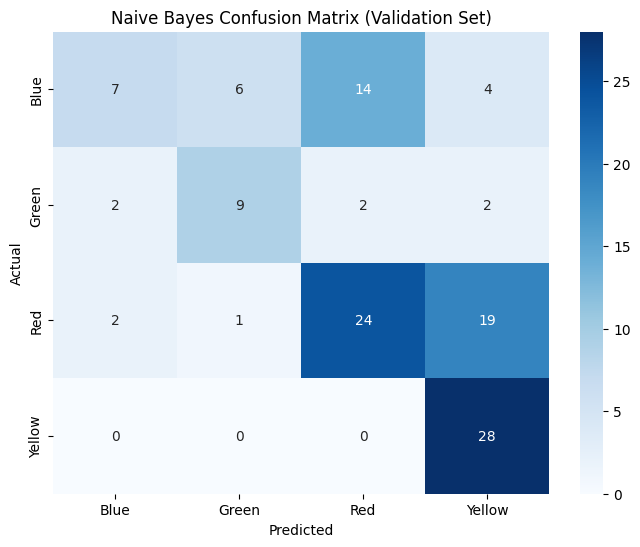


--- Making Predictions on 'Color Balls_Test.csv' ---
First 5 rows of 'Color Balls_Test.csv' with predictions:


,Room,Partitions,Rows,Columns,Predicted_Color
0,4,2,1,1,Yellow
1,3,2,1,1,Yellow
2,2,2,1,1,Yellow
3,2,2,2,2,Yellow
4,1,2,2,2,Yellow


In [ ]:
import kagglehub
import pandas as pd
import os
import glob
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB # Gaussian Naive Bayes for continuous data
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import io

# Download latest version
path = kagglehub.dataset_download("kyanichester/color-balls-decision-trees")

print("Path to dataset files:", path)

try:
    # List contents of the downloaded path to identify the correct CSV file path
    print(f"Contents of directory {path}:")
    all_files = os.listdir(path)
    for item in all_files:
        print(f"- {item}")

    train_csv_file = None
    test_csv_file = None

    for root, _, files in os.walk(path):
        for file in files:
            if 'Color Balls_Train.csv' in file:
                train_csv_file = os.path.join(root, file)
            elif 'Color Balls_Test.csv' in file:
                test_csv_file = os.path.join(root, file)

    df_train = pd.DataFrame()
    df_predict_features = pd.DataFrame()

    if train_csv_file:
        print(f"Found Train CSV file at: {train_csv_file}")
        df_train = pd.read_csv(train_csv_file)
        print("Columns in training dataset:", df_train.columns.tolist())
        print("First 5 rows of the training dataset:")
        display(df_train.head())
    else:
        print("No 'Color Balls_Train.csv' found. Cannot train model.")

    if test_csv_file:
        print(f"Found Test CSV file at: {test_csv_file}")
        df_predict_features = pd.read_csv(test_csv_file)
        print("Columns in prediction features dataset:", df_predict_features.columns.tolist())
        print("First 5 rows of the prediction features dataset:")
        display(df_predict_features.head())
    else:
        print("No 'Color Balls_Test.csv' found. Cannot make new predictions.")


    if not df_train.empty:
        # --- Naive Bayes Classification (using training data for train/test split) ---
        print("\n--- Applying Naive Bayes Classification (Training Data) ---")

        target_column = 'Color' # Assuming 'Color' is the target in the training data
        if target_column not in df_train.columns:
            print(f"Error: Target column '{target_column}' not found in training data.")
        else:
            # Separate features (X) and target (y) for training data
            X_full = df_train.drop(columns=[target_column])
            y_full = df_train[target_column]

            # Identify categorical columns for X_full
            categorical_cols_X_full = X_full.select_dtypes(include=['object', 'category']).columns

            le_X_full = {}
            for col in categorical_cols_X_full:
                le_X_full[col] = LabelEncoder()
                X_full[col] = le_X_full[col].fit_transform(X_full[col])

            le_y = LabelEncoder()
            y_encoded_full = le_y.fit_transform(y_full)

            # Split training data into training and validation sets
            X_train, X_test, y_train, y_test = train_test_split(X_full, y_encoded_full, test_size=0.3, random_state=42)

            # Initialize and train the Gaussian Naive Bayes model
            model = GaussianNB()
            model.fit(X_train, y_train)

            # Make predictions on the validation set
            y_pred = model.predict(X_test)

            # Evaluate the model
            accuracy = accuracy_score(y_test, y_pred)
            print(f"Naive Bayes Accuracy on validation set: {accuracy:.2f}")

            print("\nClassification Report on validation set:")
            report_str = classification_report(y_test, y_pred, target_names=le_y.classes_)
            print(report_str)

            # Visualize Classification Report
            report_data = pd.read_csv(io.StringIO(report_str), sep=r'\s\s+', engine='python', skipinitialspace=True, index_col=0)
            report_data = report_data.iloc[:-1, :3] # Exclude 'accuracy', 'macro avg', 'weighted avg' rows and 'support' column
            report_data.columns = ['precision', 'recall', 'f1-score']

            report_data_melted = report_data.reset_index().melt(id_vars='index', var_name='metric', value_name='score')

            plt.figure(figsize=(10, 6))
            sns.barplot(x='index', y='score', hue='metric', data=report_data_melted, palette='viridis')
            plt.title('Naive Bayes Classification Report (Validation Set)')
            plt.xlabel('Class')
            plt.ylabel('Score')
            plt.ylim(0, 1) # Scores are between 0 and 1
            plt.xticks(rotation=45, ha='right')
            plt.tight_layout()
            plt.show()

            # Confusion Matrix
            cm = confusion_matrix(y_test, y_pred)
            plt.figure(figsize=(8, 6))
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                        xticklabels=le_y.classes_, yticklabels=le_y.classes_)
            plt.title('Naive Bayes Confusion Matrix (Validation Set)')
            plt.xlabel('Predicted')
            plt.ylabel('Actual')
            plt.show()

            # --- Make Predictions on the unlabeled Test Dataset ('Color Balls_Test.csv') ---
            if not df_predict_features.empty:
                print("\n--- Making Predictions on 'Color Balls_Test.csv' ---")
                X_predict = df_predict_features.copy() # Make a copy to avoid modifying original df

                # Apply the same label encoding to features of the prediction dataset
                # Only encode columns that were present and encoded in the training data
                for col in categorical_cols_X_full:
                    if col in X_predict.columns and col in le_X_full:
                        # Use transform, not fit_transform, as the encoder is already fitted
                        X_predict[col] = le_X_full[col].transform(X_predict[col])
                    else:
                        print(f"Warning: Feature '{col}' from training data not found or encoded in prediction data.")

                predictions_encoded = model.predict(X_predict)
                predictions_original_labels = le_y.inverse_transform(predictions_encoded)

                df_predict_features['Predicted_Color'] = predictions_original_labels
                print("First 5 rows of 'Color Balls_Test.csv' with predictions:")
                display(df_predict_features.head())
            else:
                print("Cannot make predictions as 'Color Balls_Test.csv' was not loaded.")
    else:
        print("Training DataFrame 'df_train' is empty. Cannot perform machine learning tasks.")

except Exception as e:
    print(f"Error processing dataset: {e}")